# Project 27 — Customer Segmentation for Retail Businesses
**Objective:** compare three unsupervised clustering approaches and assign new retail customers. The bundled data are simulated; no real customer data or labels are used.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
from project import ROOT, FEATURES, clean, train, predict
path = ROOT / "data/customers.csv"
df, audit = clean(path)
print(audit)
display(df.head(), df[FEATURES].describe())

{'raw_rows': 1200, 'valid_rows': 1200, 'removed_rows': 0}


,customer_id,spend_90d,orders_90d,recency_days,favorite_product_share
0,SIM0001,0.00,0.0,102.0,0.964
1,SIM0002,1128.51,17.0,0.0,0.270
2,SIM0003,113.45,3.0,34.0,0.758
3,SIM0004,602.29,20.0,4.0,0.358
4,SIM0005,104.20,5.0,25.0,0.565


,spend_90d,orders_90d,recency_days,favorite_product_share
count,1200.000000,1200.000000,1200.000000,1200.000000
mean,395.884075,9.860000,41.927500,0.560273
std,459.364708,10.318873,47.850377,0.214102
min,0.000000,0.000000,0.000000,0.000000
25%,38.195000,1.000000,6.000000,0.390000
50%,163.485000,5.000000,18.500000,0.564000
75%,642.730000,17.000000,64.250000,0.729250
max,1964.780000,43.000000,218.000000,1.000000


## Preprocessing and model comparison
The training function uses an 80/20 customer split, fixed log1p transforms and a scaler fitted only on training data. It compares K-Means, Ward hierarchical and DBSCAN. The largest K-Means k within 0.025 silhouette of the best K-Means is chosen to support more granular campaigns.

In [2]:
summary = train(path)
display(pd.read_csv(ROOT / "outputs/model_comparison.csv").round(3))

{
  "source": "synthetic",
  "raw_rows": 1200,
  "valid_rows": 1200,
  "removed_rows": 0,
  "training_rows": 960,
  "test_rows": 240,
  "selected_k": 3,
  "training": {
    "clusters": 3,
    "coverage": 1.0,
    "silhouette": 0.5301722684485156,
    "davies_bouldin": 0.6678521150029946
  },
  "test": {
    "clusters": 3,
    "coverage": 1.0,
    "silhouette": 0.5216419089990285,
    "davies_bouldin": 0.6952980448830388
  },
  "review_margin_threshold": 0.766216988644242,
  "test_review_flags": 25,
  "pca_variance": 0.9293739535492764
}


,algorithm,setting,clusters,coverage,silhouette,davies_bouldin
0,K-Means,2,2,1.000,0.538,0.703
1,Hierarchical,2,2,1.000,0.537,0.704
2,K-Means,3,3,1.000,0.530,0.668
3,Hierarchical,3,3,1.000,0.526,0.662
4,K-Means,4,4,1.000,0.443,0.928
5,Hierarchical,4,4,1.000,0.426,0.990
6,K-Means,5,5,1.000,0.448,0.886
7,Hierarchical,5,5,1.000,0.425,0.873
8,K-Means,6,6,1.000,0.396,1.035
9,Hierarchical,6,6,1.000,0.382,1.053


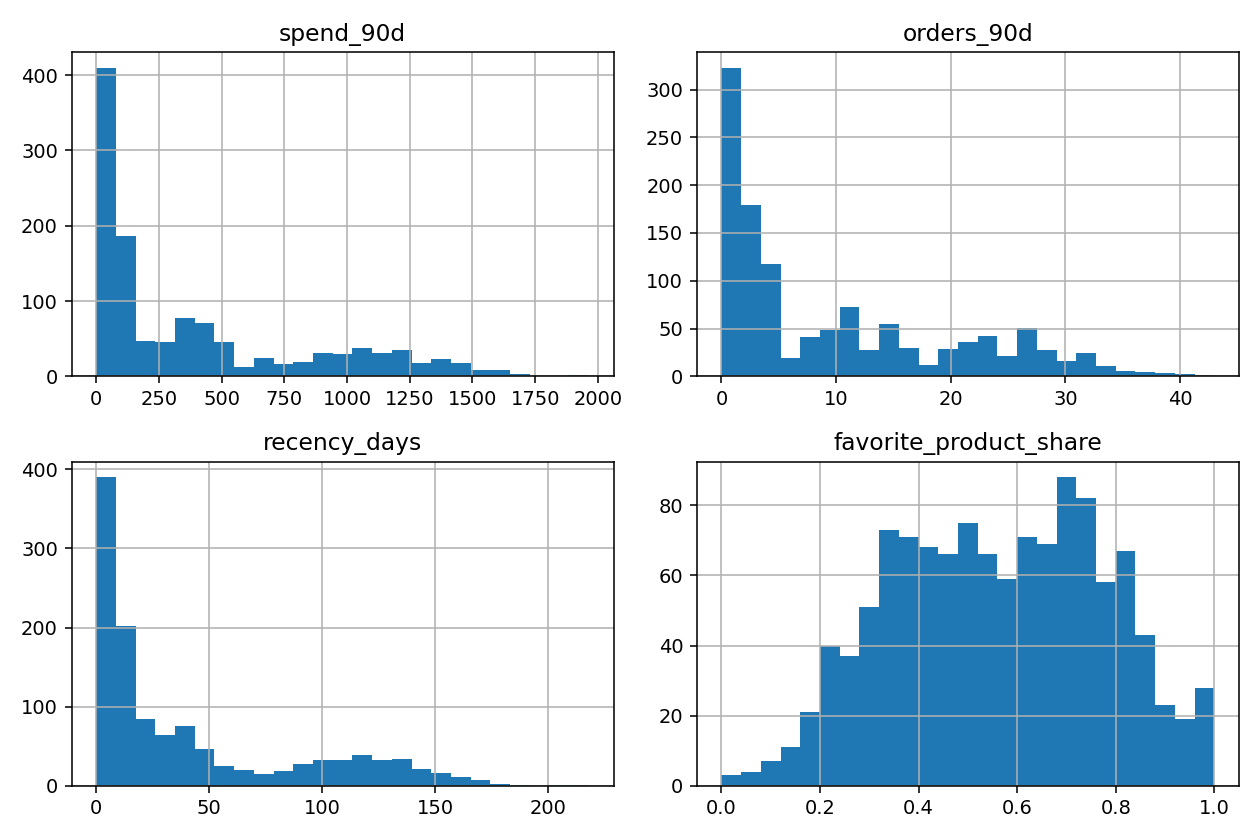

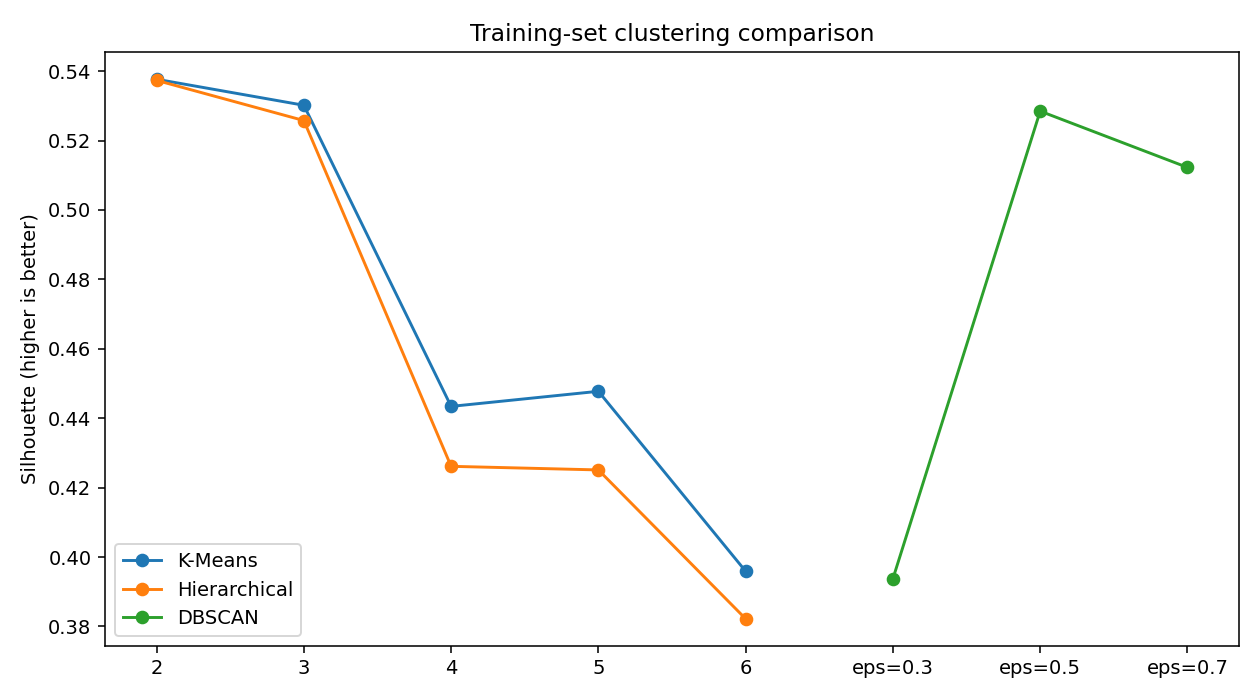

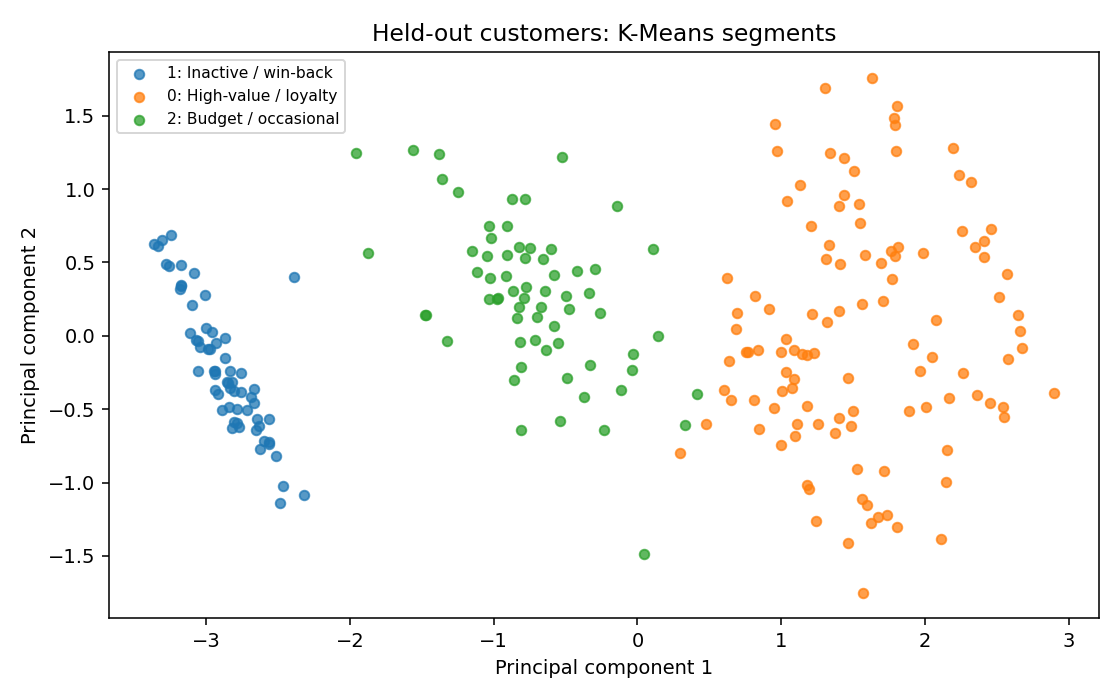

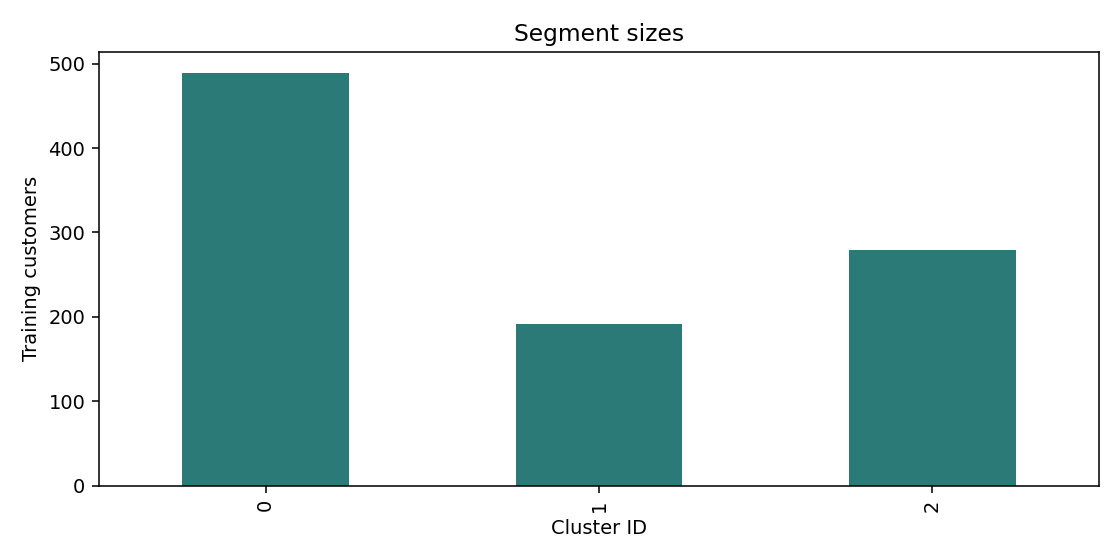

In [3]:
for file in ["feature_distributions.png", "comparison.png", "segments.png", "segment_sizes.png"]:
    display(Image(filename=str(ROOT / "outputs" / file)))

## Segment profiles and error/ambiguity analysis
A small gap between nearest and second-nearest centroid distances indicates uncertain assignment; it is not a probability. The held-out evaluation uses frozen centroids.

In [4]:
display(pd.read_csv(ROOT / "outputs/segment_profiles.csv"))
display(pd.read_csv(ROOT / "outputs/ambiguous_customers.csv").head())

,segment,spend_90d,orders_90d,recency_days,favorite_product_share,customers,name,action
0,0,738.210,18.104,7.391,0.394,489,High-value / loyalty,Offer loyalty benefits or relevant premium pro...
1,1,0.024,0.031,124.141,0.802,192,Inactive / win-back,Offer an opt-in reminder or win-back campaign.
2,2,86.679,2.796,40.810,0.668,279,Budget / occasional,Test affordable bundles and clear value offers.


,customer_id,spend_90d,orders_90d,recency_days,favorite_product_share,segment,centroid_margin,review_flag
0,SIM0378,386.95,3.0,15.0,0.440,2,0.006211,True
1,SIM0637,135.08,5.0,21.0,0.408,2,0.017218,True
2,SIM1148,68.34,5.0,19.0,0.375,0,0.019192,True
3,SIM0082,122.59,3.0,8.0,0.395,0,0.253760,True
4,SIM0894,43.17,1.0,60.0,0.981,2,0.276912,True


## Try a new customer
Edit these four values: spend (GBP), orders, recency days and favorite-product share (0–1).

In [5]:
spend, orders, recency, product_share = 380, 11, 11, 0.35
predict([spend, orders, recency, product_share])

{'segment': 0,
 'name': 'High-value / loyalty',
 'action': 'Offer loyalty benefits or relevant premium products.',
 'review_flag': False,
 'centroid_margin': 1.449,
 'source': 'synthetic'}

## Conclusion and ethics
Three clustering approaches were compared. The selected K-Means solution supports direct assignment of new customers and human-review flags. Results are illustrative only because simulated data may overstate structure. Do not infer sensitive attributes or deny services from cluster membership. Real-data import is optional; see README.